# Separating pulses into increasing / decreasing soil-moisture cases (any year)

In [1]:
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
YEAR = 2024
SFX = {2024: "_2024", 2026: "", 2025: "_2025"}[YEAR]
DIR = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets"
file = f"{DIR}/lowCF_filtered_merged_pps_smap_no2_domsoil_15cols_MCD12Q1mask{SFX}.parquet"
output_file = f"{DIR}/lowCF_filtered_merged_with_incdec_MCD12Q1mask{SFX}.parquet"

WINDOW_HOURS = 24 * 5    
MIN_POINTS = 20
HOUR_MIN, HOUR_MAX = 10, 18  # pulse start window (local) used for the plots
COLORS = {"increasing": "#2a78d6", "decreasing": "#eb6834"}

In [3]:
df = pd.read_parquet(file, engine="pyarrow")
df["pulse_start"] = df["pulse_start"].astype(str).eq("True")
df["datetime"] = pd.to_datetime(df["datetime"])
df["datetime_local"] = pd.to_datetime(df["datetime_local"])
keys = ["grid_lat", "grid_lon", "datetime"]

n_dup = df.duplicated(keys).sum()
n_off = (df["datetime"].dt.minute != 0).sum()
print(f"{YEAR}: {len(df):,} rows | duplicate cell-hours: {n_dup:,} | off-the-hour rows: {n_off:,} | pulses: {df['pulse_start'].sum():,}")
if n_dup or n_off:
    print("WARNING: this is an OLD merged file (pre-fix). Rerun R_2_1 (memory-safe) + R_2_2 for this year. "
          "Collapsing duplicates here so the numbers below are at least not double-counted.")
    df = df[df["datetime"].dt.minute == 0]
    df = df.groupby(keys, sort=False, as_index=False).first()
    df["pulse_start"] = df["pulse_start"].astype(bool)

df = df.sort_values(keys).reset_index(drop=True)
pulse_df = df.loc[df["pulse_start"], keys + ["datetime_local"]].reset_index(drop=True)
print(f"pulses: {len(pulse_df):,}")

2024: 38,482,560 rows | duplicate cell-hours: 0 | off-the-hour rows: 0 | pulses: 16,583
pulses: 16,583


## Pre-pulse soil-moisture slope

In [4]:
win = np.timedelta64(WINDOW_HOURS, "h")
sm = df.loc[df["sm_surface"].notna(), keys + ["sm_surface"]]
cell_sm = {k: (g["datetime"].to_numpy(), g["sm_surface"].to_numpy()) for k, g in sm.groupby(["grid_lat", "grid_lon"])}

slopes = np.full(len(pulse_df), np.nan)
for i, (lat, lon, t0) in enumerate(pulse_df[keys].itertuples(index=False)):
    if (lat, lon) not in cell_sm:
        continue
    t, y = cell_sm[(lat, lon)]
    t0 = np.datetime64(t0, "ns")
    a, b = np.searchsorted(t, t0 - win), np.searchsorted(t, t0)   # [t0-120h, t0)
    if b - a >= MIN_POINTS:
        x = (t[a:b] - t[a]) / np.timedelta64(1, "h")
        slopes[i] = np.polyfit(x, y[a:b], 1)[0]
del sm, cell_sm; gc.collect()

slope_df = pulse_df.assign(pre_slope=slopes)
slope_df["sm_class"] = np.select([slope_df["pre_slope"] > 0, slope_df["pre_slope"] < 0],
                                 ["increasing", "decreasing"], default="no data")
slope_df["hour"] = slope_df["datetime_local"].dt.hour
print(slope_df["sm_class"].value_counts())

sm_class
decreasing    10556
increasing     6025
no data           2
Name: count, dtype: int64


In [6]:
df = df.merge(slope_df[keys + ["pre_slope", "sm_class"]], on=keys, how="left")
assert df.duplicated(keys).sum() == 0
Path(output_file).parent.mkdir(parents=True, exist_ok=True)
df.to_parquet(output_file, engine="pyarrow", index=False)
print("saved:", output_file)

saved: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_filtered_merged_with_incdec_MCD12Q1mask_2024.parquet


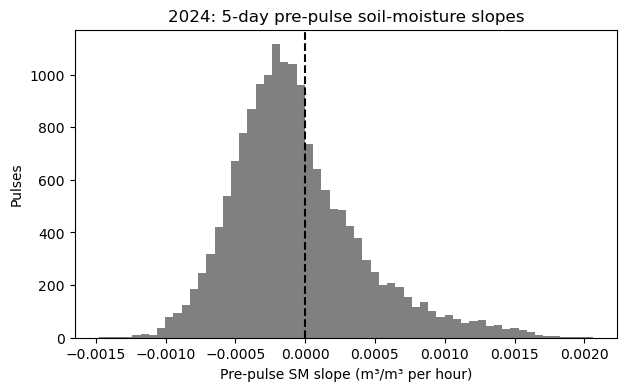

In [7]:
plt.figure(figsize=(7, 4))
plt.hist(slope_df["pre_slope"].dropna(), bins=60, color="grey")
plt.axvline(0, ls="--", c="k")
plt.xlabel("Pre-pulse SM slope (m³/m³ per hour)"); plt.ylabel("Pulses")
plt.title(f"{YEAR}: 5-day pre-pulse soil-moisture slopes")
plt.show()

## Hour of day

all hours:
 sm_class
decreasing    63.7
increasing    36.3
10:00-18:59 local (4,395 pulses):
 sm_class
decreasing    63.6
increasing    36.4


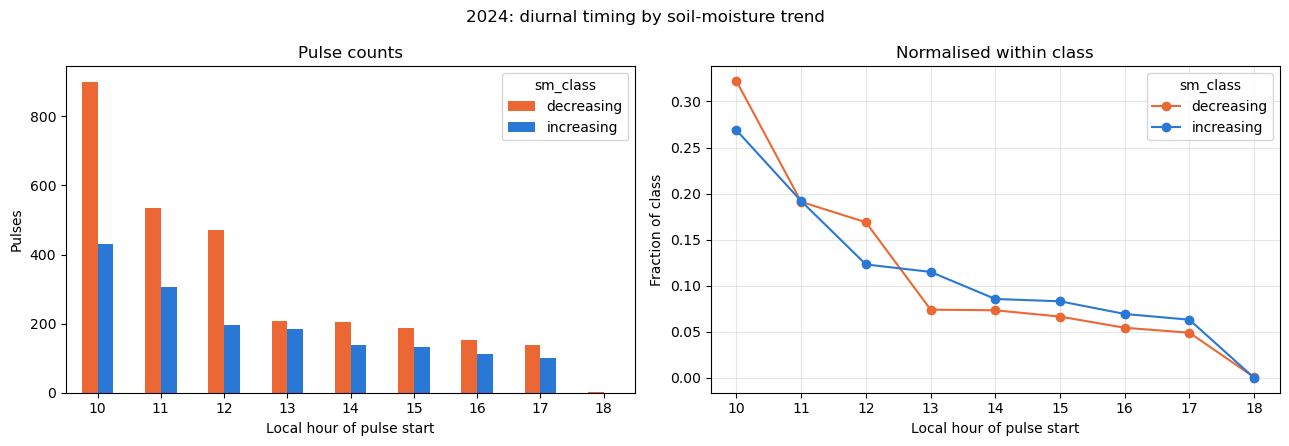

In [8]:
cls = slope_df[slope_df["sm_class"].isin(["increasing", "decreasing"])]
win_df = cls[cls["hour"].between(HOUR_MIN, HOUR_MAX)]

print("all hours:\n", cls["sm_class"].value_counts(normalize=True).mul(100).round(1).to_string())
print(f"{HOUR_MIN}:00-{HOUR_MAX}:59 local ({len(win_df):,} pulses):\n",
      win_df["sm_class"].value_counts(normalize=True).mul(100).round(1).to_string())

counts = win_df.groupby(["hour", "sm_class"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
counts.plot.bar(ax=ax[0], color=[COLORS[c] for c in counts.columns], rot=0)
ax[0].set(xlabel="Local hour of pulse start", ylabel="Pulses", title="Pulse counts")
(counts / counts.sum()).plot(ax=ax[1], marker="o", color=[COLORS[c] for c in counts.columns])
ax[1].set(xlabel="Local hour of pulse start", ylabel="Fraction of class", title="Normalised within class")
ax[1].grid(alpha=0.3)
fig.suptitle(f"{YEAR}: diurnal timing by soil-moisture trend")
plt.tight_layout(); plt.show()

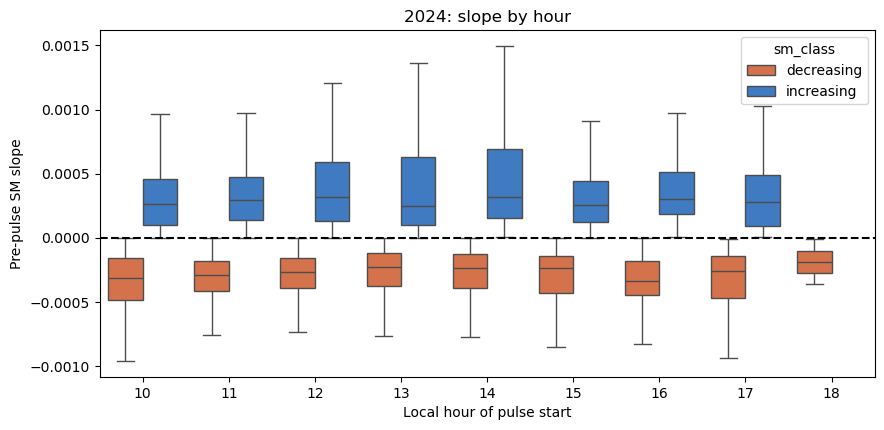

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=win_df, x="hour", y="pre_slope", hue="sm_class", palette=COLORS, showfliers=False, ax=ax)
ax.axhline(0, ls="--", c="k")
ax.set(xlabel="Local hour of pulse start", ylabel="Pre-pulse SM slope", title=f"{YEAR}: slope by hour")
plt.show()

## Precipitation leading up to pulses

In [10]:
BIN_H = 6
evs = win_df.reset_index(drop=True)
evs["event_id"] = np.arange(len(evs))

# all hourly rows in the 120 h before (and including) each pulse, per cell
pr = df.loc[df["h_precip_mm"].notna(), keys + ["h_precip_mm"]]
cell_pr = {k: (g["datetime"].to_numpy(), g["h_precip_mm"].to_numpy()) for k, g in pr.groupby(["grid_lat", "grid_lon"])}
del pr; gc.collect()

rows = []
for eid, lat, lon, t0, c in evs[["event_id", "grid_lat", "grid_lon", "datetime", "sm_class"]].itertuples(index=False):
    if (lat, lon) not in cell_pr:
        continue
    t, p = cell_pr[(lat, lon)]
    t0 = np.datetime64(t0, "ns")
    a, b = np.searchsorted(t, t0 - win), np.searchsorted(t, t0, side="right")
    lag = ((t[a:b] - t0) / np.timedelta64(1, "h")).astype(int)        # -120 ... 0
    rows.append(pd.DataFrame({"event_id": eid, "sm_class": c, "lag_hours": lag, "h_precip_mm": p[a:b]}))
events_df = pd.concat(rows, ignore_index=True)
del rows, cell_pr; gc.collect()

# 6-h bins: bin label = end of the bin (0 = the pulse hour and the 5 h before it)
events_df["bin"] = -((-events_df["lag_hours"]) // BIN_H) * BIN_H
per_ev = events_df.groupby(["sm_class", "event_id", "bin"])["h_precip_mm"].agg(["sum", "count"]).reset_index()
per_ev = per_ev[per_ev["count"] >= BIN_H // 2]           # need at least half the hours in the bin
per_ev["wet"] = per_ev["sum"] >= 0.1

rng = np.random.default_rng(0)
def boot_ci(v, n=500):
    v = v.to_numpy()
    m = rng.choice(v, (n, len(v))).mean(1)
    return pd.Series({"mean": v.mean(), "lo": np.percentile(m, 2.5), "hi": np.percentile(m, 97.5)})

stats = per_ev.groupby(["sm_class", "bin"])["sum"].apply(boot_ci).unstack().reset_index()
wet = per_ev.groupby(["sm_class", "bin"])["wet"].mean().mul(100).reset_index()

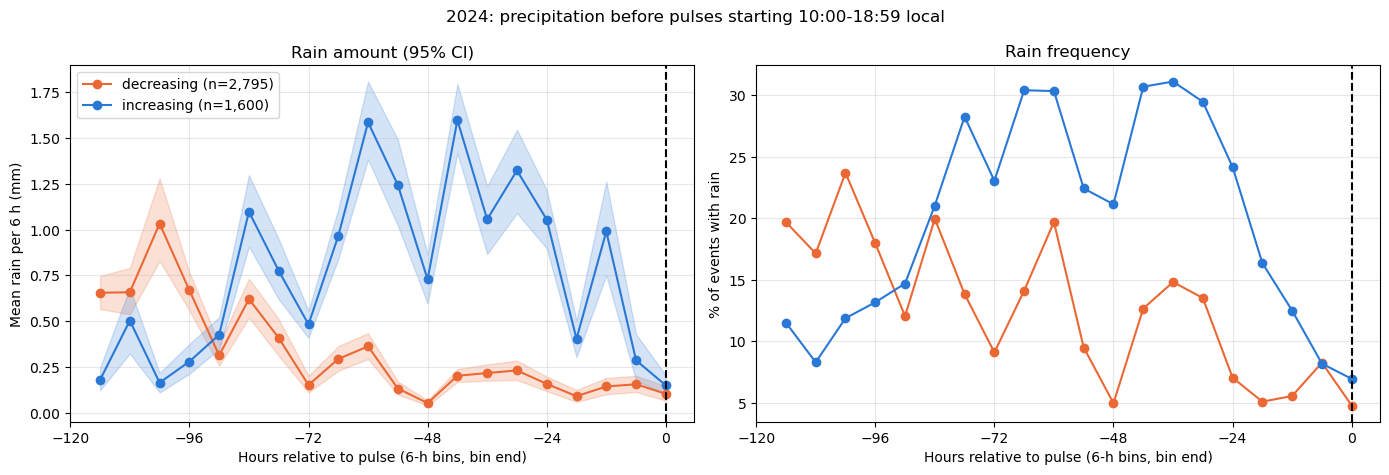

           rain_5d        rain_24h       
              mean median     mean median
sm_class                                 
decreasing    4.05   1.22     0.32    0.0
increasing   10.77   8.59     1.31    0.0


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for c, g in stats.groupby("sm_class"):
    n = evs["sm_class"].eq(c).sum()
    ax[0].plot(g["bin"], g["mean"], marker="o", color=COLORS[c], label=f"{c} (n={n:,})")
    ax[0].fill_between(g["bin"], g["lo"], g["hi"], color=COLORS[c], alpha=0.2)
for c, g in wet.groupby("sm_class"):
    ax[1].plot(g["bin"], g["wet"], marker="o", color=COLORS[c], label=c)
for a in ax:
    a.axvline(0, ls="--", c="k")
    a.set_xlabel("Hours relative to pulse (6-h bins, bin end)")
    a.set_xticks(range(-WINDOW_HOURS, 1, 24)); a.grid(alpha=0.3)
ax[0].set(ylabel=f"Mean rain per {BIN_H} h (mm)", title="Rain amount (95% CI)")
ax[1].set(ylabel="% of events with rain", title="Rain frequency")
ax[0].legend()
fig.suptitle(f"{YEAR}: precipitation before pulses starting {HOUR_MIN}:00-{HOUR_MAX}:59 local")
plt.tight_layout(); plt.show()
tot = per_ev.groupby(["sm_class", "event_id"]).agg(
    rain_5d=("sum", "sum"),
    rain_24h=("sum", lambda s: s[per_ev.loc[s.index, "bin"] > -24].sum()))
print(tot.groupby("sm_class").agg(["mean", "median"]).round(2))